## Week 2.3: Temperature, humidity and wind in the atmospheric boundary layer

In [11]:
import numpy as np
import matplotlib.pyplot as plt

### 1a.

We know that:

$$
SHF + LHF+SW_{net}+LW_{net}+G=0
$$

The question states that there is a zero ground heat flux, so $G = 0$. Furthermore, the constant net radiation flux at the ground surface is given, which means:

$$
SW_{net}+LW_{net} = 400 [W/m^2]
$$

Therefore, the sum of the latent en sensible heat fluxes must be equal to $-400 [W/m^2]$.

In this situation, the values for SHF and LHF can range between 0 and -400, as long as their sum is still equal to $-400 [W/m^2]$.

### 1b.

In this scenario, there is no evaporation, so we can say that $LHF = 0$ and therefore $SHF = -400$. With that, we can calculate $\overline{w'T'}$:

$$
\overline{w'T'}= \frac{SHF}{\rho c_p}
$$

which gives a value of $-0.332 [mK/s]$. With this value, we can calculate the change in temperature over time using the following formula:

$$
\frac{\partial \overline{T}}{\partial t} = -\frac{\partial \overline{w'T'}}{\partial z}
$$

Since there is no ground heat flux, $\partial \overline{w'T'}$ at the ground will be equal to zero, which then gives a final answer of $-1.194 K/h$

In [12]:
flux = 400

# Define initla parameters
density = 1.2 #kg/m^3
h = 1000 #m
SHF = 400 # No evaporation, so LHF = 0, W/m^2
cp = 1005 #?


# Calculate wT
wT__ = SHF/(density*cp)
print(f"wT__ value: {wT__:.3f} mK/s")

# Calculate the change in temp. over time
dTdt = -(0-wT__)/h
print(f"Heating rate at z = {h} m: {dTdt*3600:.3f} K/h")

wT__ value: 0.332 mK/s
Heating rate at z = 1000 m: 1.194 K/h


### 1c.

We first the define the formula for $e_{sat}$:

$$
e_{sat,z} = 610.78 e^{\frac{17.2694(T - 273.16)}{T - 35.86}}
$$

We now want to calculate the change of the saturation specific humididty at the top of the boundary layer. For that we use the following equation:

$$
q_{sat} = \frac{R_d}{R_v}\frac{e_{sat}}{p} [1]
$$

It is assumed that the pressure is constant, which we can calculate using:

$$
p = \rho R_d T_0 [2]
$$

Where $T_0$ is the initial temperature.

We can rewrite equation [1] as:

$$
\frac{\partial}{\partial t}q_{sat} =\frac{\partial}{\partial t} \frac{R_d}{R_v}\frac{e_{sat}}{p} [3.1]
$$

$$
\frac{\partial q_{sat}}{\partial t} = \frac{R_d}{R_v}\frac{1}{p} \frac{\partial e_{sat}}{\partial t}[3.2]
$$

$$
\frac{\partial q_{sat}}{\partial t} = \frac{R_d}{R_v}\frac{1}{p}   \frac{ e_{sat}(T_1) - e_{sat}(T_0)}{T_1-T_0}[3.3]
$$

Using equation 3.3, we find a change of $8.842 [g/kg/h]$

In [13]:
# Define parameters and constants
Rv = 461.5
Rd = 287.04

T0 = 293 # Default value
T1 = T0 + dTdt # Based on value from 1b

# Define e_sat function, which only depends on T
def e_sat(T):
    esat = 610.78*np.exp(17.2694 * (T -273.16) / (T - 35.86))
    return esat

dqdt=((Rd/Rv)*(e_sat(T1)-e_sat(T0))/(density*T0*Rd))/(T1-T0)*1000
print(f"change in q_sat: {dqdt:.3f} g/kg/h")

change in q_sat: 0.884 g/kg/h


### 1d.



In this scenario, $LHF = -400$ and $SHF = 0$. With the $LHF$ we can now use the following formula:

$$
LHF = \rho \lambda_l \overline{w'q_v'} [1]
$$

where $\lambda_l$ is the latent heat of vaporization for water, which is equal to $2.26\cdot 10^6 [J/kg]$.

We rewrite equation 1 to:

$$
\overline{w'q_v'} = \frac{LHF}{\rho \lambda_l} [2]
$$

We can then say that:

$$
\frac{\partial\overline{w'q_v'}}{\partial z} = \frac{0-\frac{LHF}{\rho \lambda_l}}{0-h} = \frac{\partial \overline{q_v}}{\partial t}
$$

When we calculate this, we get a value of $0.531 [g/kg/h]$

In [18]:
# New scenario value
LHF = 400

# Constant
lambda_l = 2.26e6

# Calculate wqv__
wqv__ = LHF/(density*lambda_l)

# Calcualte final answer
dq_vdt = (0 - wqv__) / (0 - h) * 1000 * 3600
print(f"dqv/dt = {dq_vdt:.3f} g/kg/h")

dqv/dt = 0.531 g/kg/h


### 1e.

We now assume the following two things:

$$
LHF = \rho \lambda_l \overline{w'q_v'} ≠ 0 [1.1]
$$

$$
SHF= \rho c_p \overline{w'T'} ≠ 0 [1.2]
$$

We now want a  constant relative humidity at the top of the atmosphere, so:

$$
\frac{\partial RH}{\partial t}=0 [2]
$$

Where 
$$
RH = \frac{q_v}{q_{sat}} [3.1]
$$

$$
\frac{\partial RH}{\partial t}=\frac{\partial}{\partial t}\frac{q_v}{q_{sat}}=0 [3.2]
$$

Which is rewritten as:

$$
\frac{\partial RH}{\partial t}=\frac{1}{q_{sat}}\frac{\partial q_v}{\partial t} - \frac{q_v}{q_{sat}^2}\frac{\partial q_{sat}}{\partial t}=0 [4.1]
$$


$$
\frac{\partial q_v}{\partial t} = \frac{q_v}{q_{sat}}\frac{\partial q_{sat}}{\partial t} [4.2]
$$

$$
\frac{\partial q_v}{\partial t} = RH\frac{\partial q_{sat}}{\partial T}\frac{\partial T}{\partial t} [4.3]
$$

In equation 4.3, we see the heating and moistening rate. If we want to know when RH is constant with time, then these rates must be equal to each other. Therefore, we find a solution  for SHF and LHF at:

$$
\frac{\partial q_v}{\partial t} = \frac{\partial T}{\partial t} [5]
$$

The figure below shows the heating and moistening rates with respect to $SHF$, where we can find a value for the $SHF$ where both rates are equal to each other. This is done numerically, and gives us a value for $SHF$ of $-122.45 W/m^2$ and a value for $LHF$ of $-277.55 W/m^2$.

optimal_SHF: 122.45 W/m^2
optimal_LHF: 277.55 W/m^2


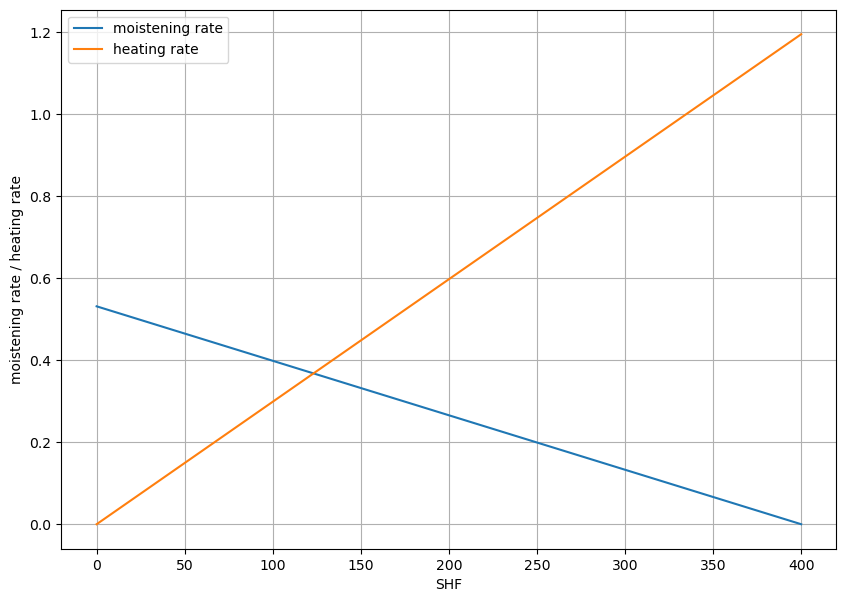

In [21]:
# Define initla parameters
density = 1.2 #kg/m^3
h = 1000 #m
SHF = np.linspace(0,flux) # No evaporation, so LHF = 0, W/m^2
cp = 1005 #?

# Calculate the change in temp. over time
wT__ = SHF/(density*cp)
dTdt = -(0-wT__)/h*3600



# New scenario value
LHF = SHF[::-1] # inverse of SHF

# Constant
lambda_l = 2.26e6

# Calculate wqv__
wqv__ = LHF/(density*lambda_l)

# Calcualte final answer
dq_vdt = (0 - wqv__) / (0 - h) * 1000 * 3600

#find where moistening rate = heating rate
optimal_SHF = SHF[np.argmin(abs(-dq_vdt+dTdt))]
optimal_LHF = flux-optimal_SHF


print(f"optimal_SHF: {optimal_SHF:.2f} W/m^2")
print(f"optimal_LHF: {optimal_LHF:.2f} W/m^2")


plt.figure(figsize=(10,7))

plt.plot(SHF,dq_vdt,label = 'moistening rate')
plt.plot(SHF,dTdt,label = 'heating rate')

plt.xlabel("SHF")
plt.ylabel("moistening rate / heating rate")

plt.grid()
plt.legend()

### 2a.

not yet done

### 2b.

![never again](figures/suffer.png)

### 2c.

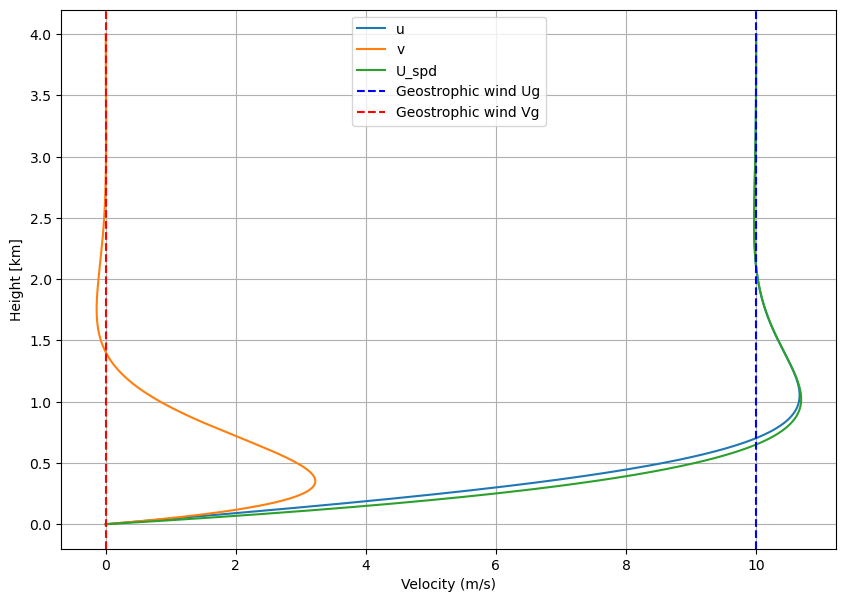

In [22]:
def velocities(Km,z,Ug):
    f = 1e-4
    gamma = np.sqrt(f/(2*Km))

    u = Ug*(1-np.exp(-gamma*z)*np.cos(gamma*z))
    v = Ug*np.exp(-gamma*z)*np.sin(gamma * z)

    U_spd = np.sqrt(u**2+v**2)
    return u, v, U_spd

z = np.linspace(0,4e3,1000)
u, v, U_spd = velocities(Km = 10, z = z, Ug = 10)

plt.figure(figsize=(10,7))
plt.plot(u,z*1e-3,label="u")
plt.plot(v,z*1e-3,label="v")
plt.plot(U_spd,z*1e-3,label='U_spd')
plt.axvline(10,label='Geostrophic wind Ug',c='b',linestyle='--')
plt.axvline(0,label='Geostrophic wind Vg',c='r',linestyle='--')

plt.xlabel("Velocity (m/s)")
plt.ylabel("Height [km]")

plt.grid()
plt.legend()

### 2d.

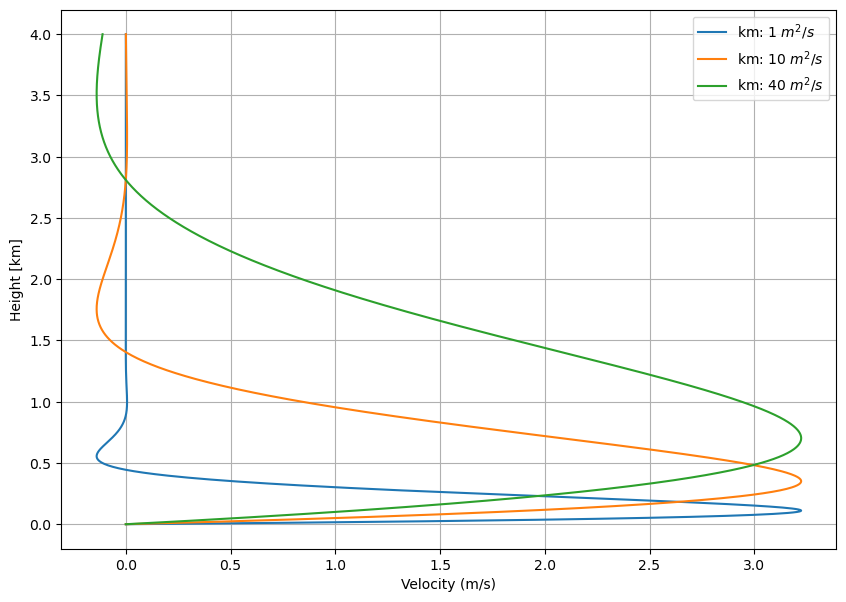

In [23]:
def velocities(Km,z,Ug):
    f = 1e-4
    gamma = np.sqrt(f/(2*Km))

    u = Ug*(1-np.exp(-gamma*z)*np.cos(gamma*z))
    v = Ug*np.exp(-gamma*z)*np.sin(gamma * z)

    U_spd = np.sqrt(u**2+v**2)
    return u, v, U_spd

z = np.linspace(0,4e3,1000)
km_list = np.array([1,10,40])
plt.figure(figsize=(10,7))


for km in km_list:
    u, v, U_spd = velocities(Km = km, z = z, Ug = 10)

    plt.plot(v,z*1e-3,label=fr"km: {km} $m^2/s$")

    plt.xlabel("Velocity (m/s)")
    plt.ylabel("Height [km]")

    plt.grid()
    plt.legend()

The wind direction does indeed depend on Km at a fixed height. For example, at a height of 2 km, we see that for km = 40 that we have a velocity of roughly 0.8 m/s, while for km = 10 it is roughly -0.2 m/s, which is negative and thus in a different direciton.

### 2e.